# XAI — Grad-CAM for the fine-tuned DenseNet121 (Run 3)


## 1. Setup and model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json, random, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

PROJECT_DIR = Path("/content/drive/MyDrive/x_ray_ds")
MODEL_PATH  = PROJECT_DIR / "models" / "run3_finetuned.keras"
CONFIG_PATH = PROJECT_DIR / "models" / "inference_config.json"
ZIP_PATH    = PROJECT_DIR / "archive (1).zip"
DATA_ROOT   = Path("/content/chest_xray_512_merged")
XAI_DIR     = PROJECT_DIR / "xai_run3"
XAI_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

with open(CONFIG_PATH) as f:
    config = json.load(f)
classes    = config["classes"]
thresholds = np.array(config["thresholds"])
IMG_SIZE   = config["img_size"]
NUM_CLASSES = len(classes)

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
assert model.output_shape[-1] == NUM_CLASSES, "Model outputs do not match the classes in inference_config.json"

print("Model:", MODEL_PATH.name, "| input:", model.input_shape, "| outputs:", NUM_CLASSES)
print("Classes:", classes)
print("GPU:", tf.config.list_physical_devices("GPU") or "not found (CPU works, just slower)")

Model: run3_finetuned.keras | input: (None, 224, 224, 3) | outputs: 14
Classes: ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Grad-CAM
The model is `normalization → DenseNet121 → GAP → Dropout → Dense(sigmoid)`.
Grad-CAM uses the last DenseNet121 feature map (7×7×1024) and the gradient of the chosen disease's **logit** (score before the sigmoid, so confident predictions still give useful gradients).

In [ ]:
# Split the model around the DenseNet121 block
base = next(l for l in model.layers if isinstance(l, tf.keras.Model))
base_pos    = model.layers.index(base)
pre_layers  = [l for l in model.layers[:base_pos] if not isinstance(l, tf.keras.layers.InputLayer)]
post_layers = model.layers[base_pos + 1:]
out_dense   = post_layers[-1]                     # Dense layer with the sigmoid
print("Before backbone:", [l.name for l in pre_layers])
print("Backbone:", base.name, "->", tuple(base.output.shape))
print("After backbone:", [l.name for l in post_layers])


def load_image(path):
    """Same preprocessing as training: RGB, resize to IMG_SIZE, values in [0, 1]."""
    if not tf.is_tensor(path):
        path = str(path)
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(img, [IMG_SIZE, IMG_SIZE]) / 255.0


def grad_cam(img, class_idx):
    """Heatmap (IMG_SIZE x IMG_SIZE, values 0-1) and probability for one image and one class."""
    x = tf.convert_to_tensor(img)[None, ...]
    with tf.GradientTape() as tape:
        for layer in pre_layers:
            x = layer(x)
        feats = base(x, training=False)
        tape.watch(feats)
        h = feats
        for layer in post_layers[:-1]:
            h = layer(h, training=False)
        logits = tf.matmul(h, out_dense.kernel) + out_dense.bias
        score  = logits[:, class_idx]
    grads   = tape.gradient(score, feats)                       # (1, 7, 7, 1024)
    weights = tf.reduce_mean(grads, axis=(1, 2))                 # importance of each feature map
    cam     = tf.nn.relu(tf.reduce_sum(feats * weights[:, None, None, :], axis=-1))[0]
    cam     = cam / (tf.reduce_max(cam) + 1e-8)
    cam     = tf.image.resize(cam[..., None], [IMG_SIZE, IMG_SIZE])[..., 0]
    prob    = float(tf.sigmoid(score)[0])
    return cam.numpy(), prob


def show_cam(ax, img, cam, title):
    ax.imshow(np.asarray(img).mean(axis=-1), cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

print("Grad-CAM ready ✅")

Before backbone: ['imagenet_norm']
Backbone: densenet121 -> (None, 7, 7, 1024)
After backbone: ['gap', 'dropout', 'disease_probabilities']
Grad-CAM ready ✅


## 3. Test images and predictions

In [ ]:
test_dir = DATA_ROOT / "test"
if not (test_dir / "test.csv").exists():
    print("Extracting the test images only ...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        members = [n for n in z.namelist() if n.startswith("chest_xray_512_merged/test/")]
        z.extractall("/content", members=members)
print("Test images:", len(list((test_dir / "images").glob("*.png"))))

test_df = pd.read_csv(test_dir / "test.csv")
test_df["Image Index"] = test_df["Image Index"].astype(str).str.strip()
test_df["labels_list"] = test_df["Finding Labels"].fillna("").apply(
    lambda s: [l.strip() for l in s.split("|") if l.strip() in classes])
test_df = test_df[test_df["labels_list"].str.len() > 0].reset_index(drop=True)   # same as training (Hernia-only removed)
test_df["image_path"] = [str(test_dir / "images" / n) for n in test_df["Image Index"]]

y_test = np.array([[c in labels for c in classes] for labels in test_df["labels_list"]], dtype=int)

test_ds = (tf.data.Dataset.from_tensor_slices(test_df["image_path"].values)
           .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(32).prefetch(tf.data.AUTOTUNE))
test_prob = model.predict(test_ds, verbose=1)
test_pred = (test_prob >= thresholds).astype(int)
print("Predictions:", test_prob.shape)

Extracting the test images only ...
Test images: 5369
168/168 ━━━━━━━━━━━━━━━━━━━━ 59s 246ms/step
Predictions: (5369, 14)


## 4. Grad-CAM — one example per disease
For each disease: the test image that truly has it and gets the **highest** probability (a correct detection). Shows what the model relies on when it is right.

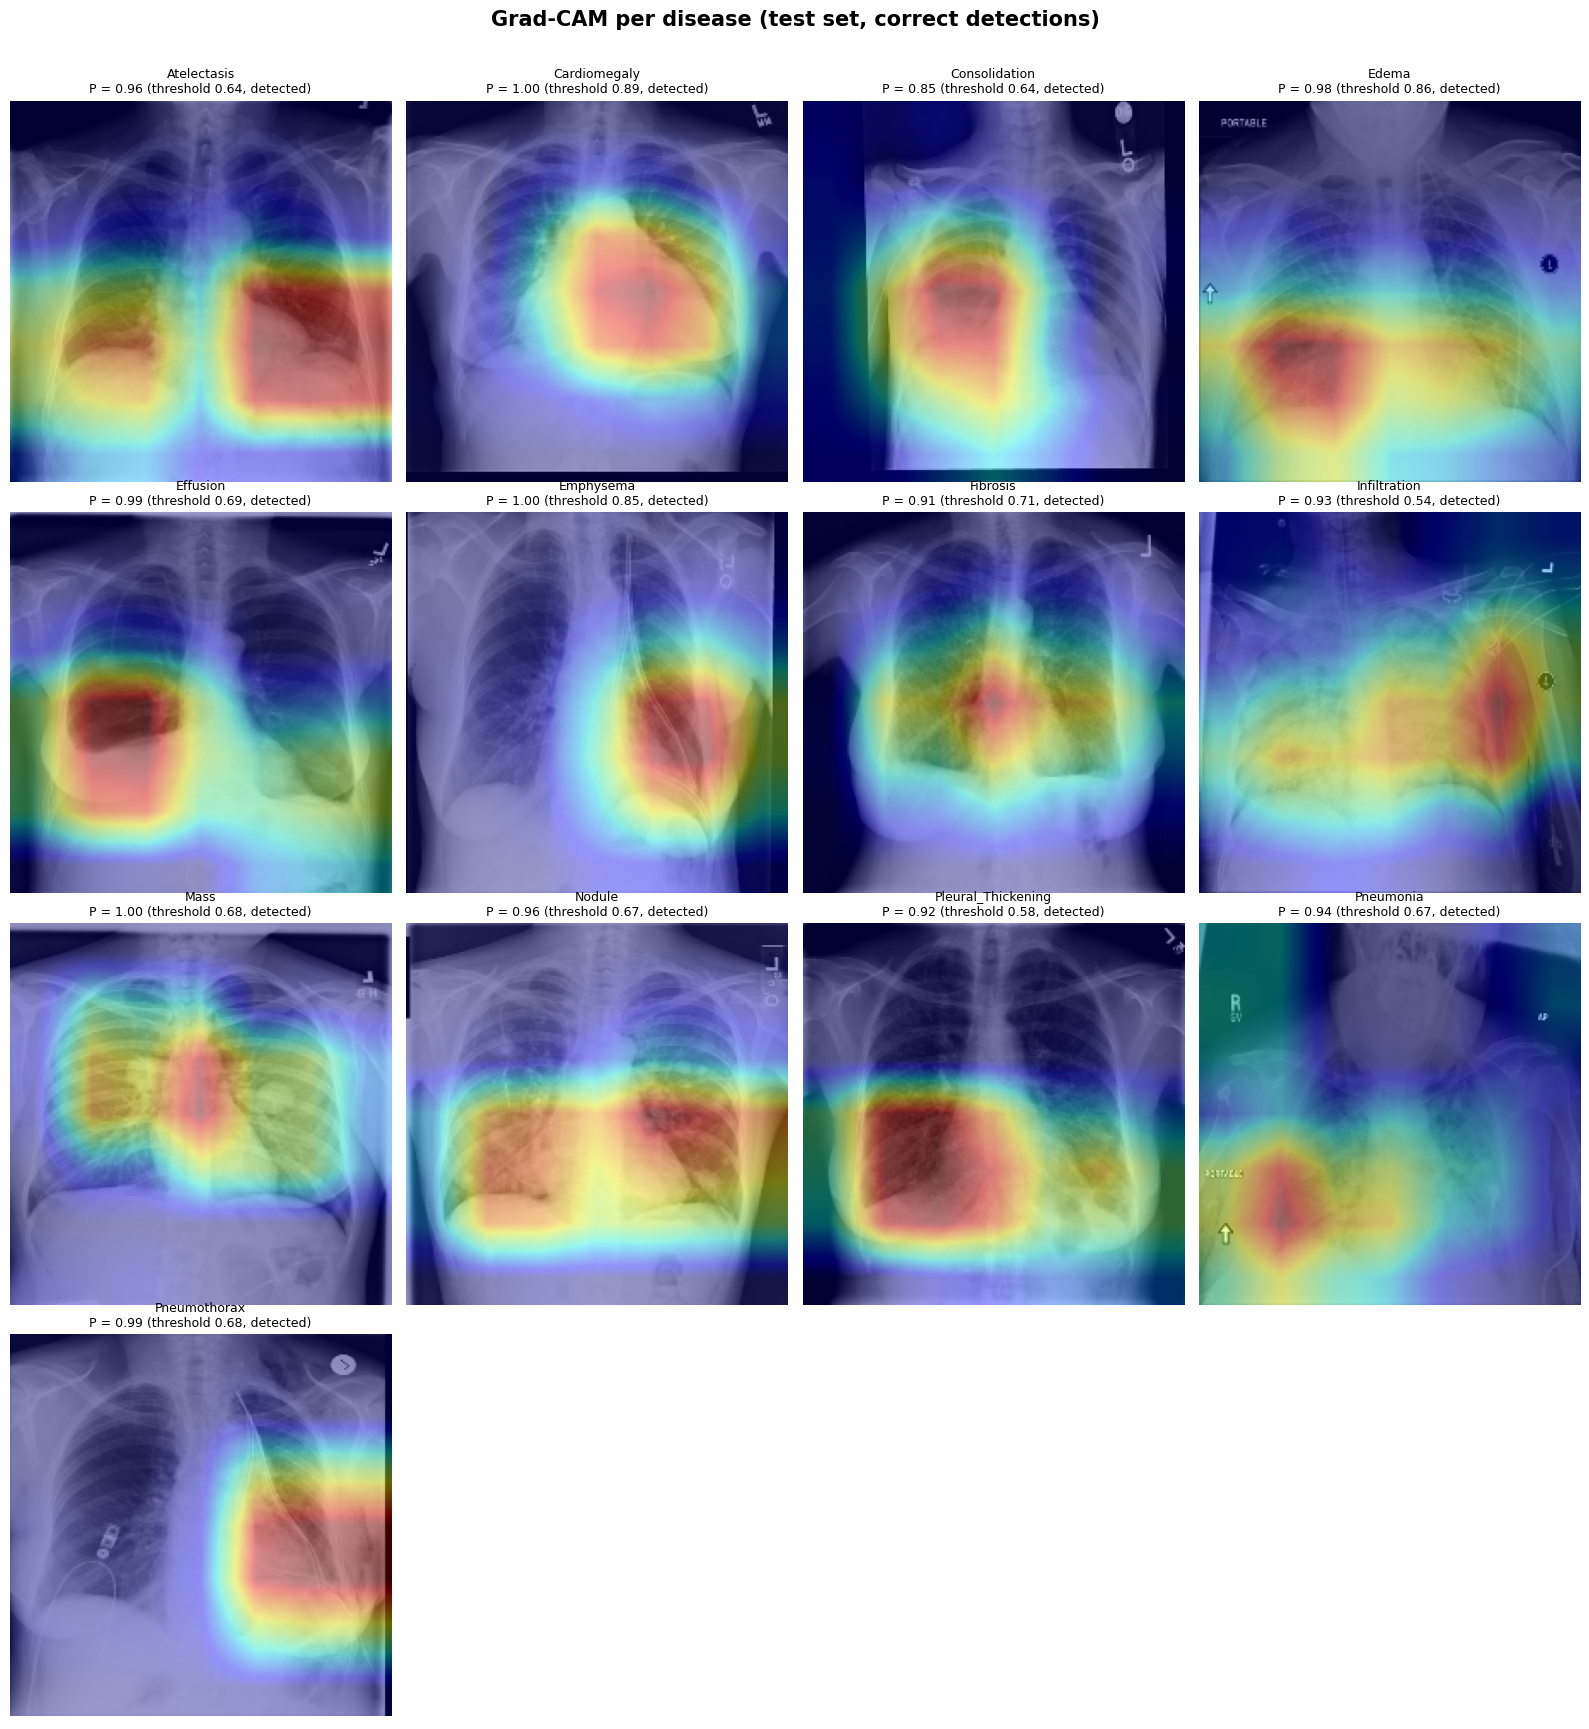

In [ ]:
diseases = [c for c in classes if c != "No Finding"]
n_cols = 4
n_rows = int(np.ceil(len(diseases) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.4 * n_rows), squeeze=False)

for ax, disease in zip(axes.flat, diseases):
    i = classes.index(disease)
    positives = np.where(y_test[:, i] == 1)[0]
    if len(positives) == 0:
        ax.set_title(f"{disease}\n(no test images)", fontsize=9); ax.axis("off")
        continue
    best = positives[np.argmax(test_prob[positives, i])]
    img = load_image(test_df.loc[best, "image_path"])
    cam, prob = grad_cam(img, i)
    status = "detected" if prob >= thresholds[i] else "below threshold"
    show_cam(ax, img, cam, f"{disease}\nP = {prob:.2f} (threshold {thresholds[i]:.2f}, {status})")
for ax in axes.flat[len(diseases):]:
    ax.axis("off")

plt.suptitle("Grad-CAM per disease (test set, correct detections)", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(XAI_DIR / "gradcam_per_disease.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Grad-CAM — random test images
Each row: the X-ray, then the heatmaps of the 3 diseases the model rates highest. ✔ = above that disease's threshold.

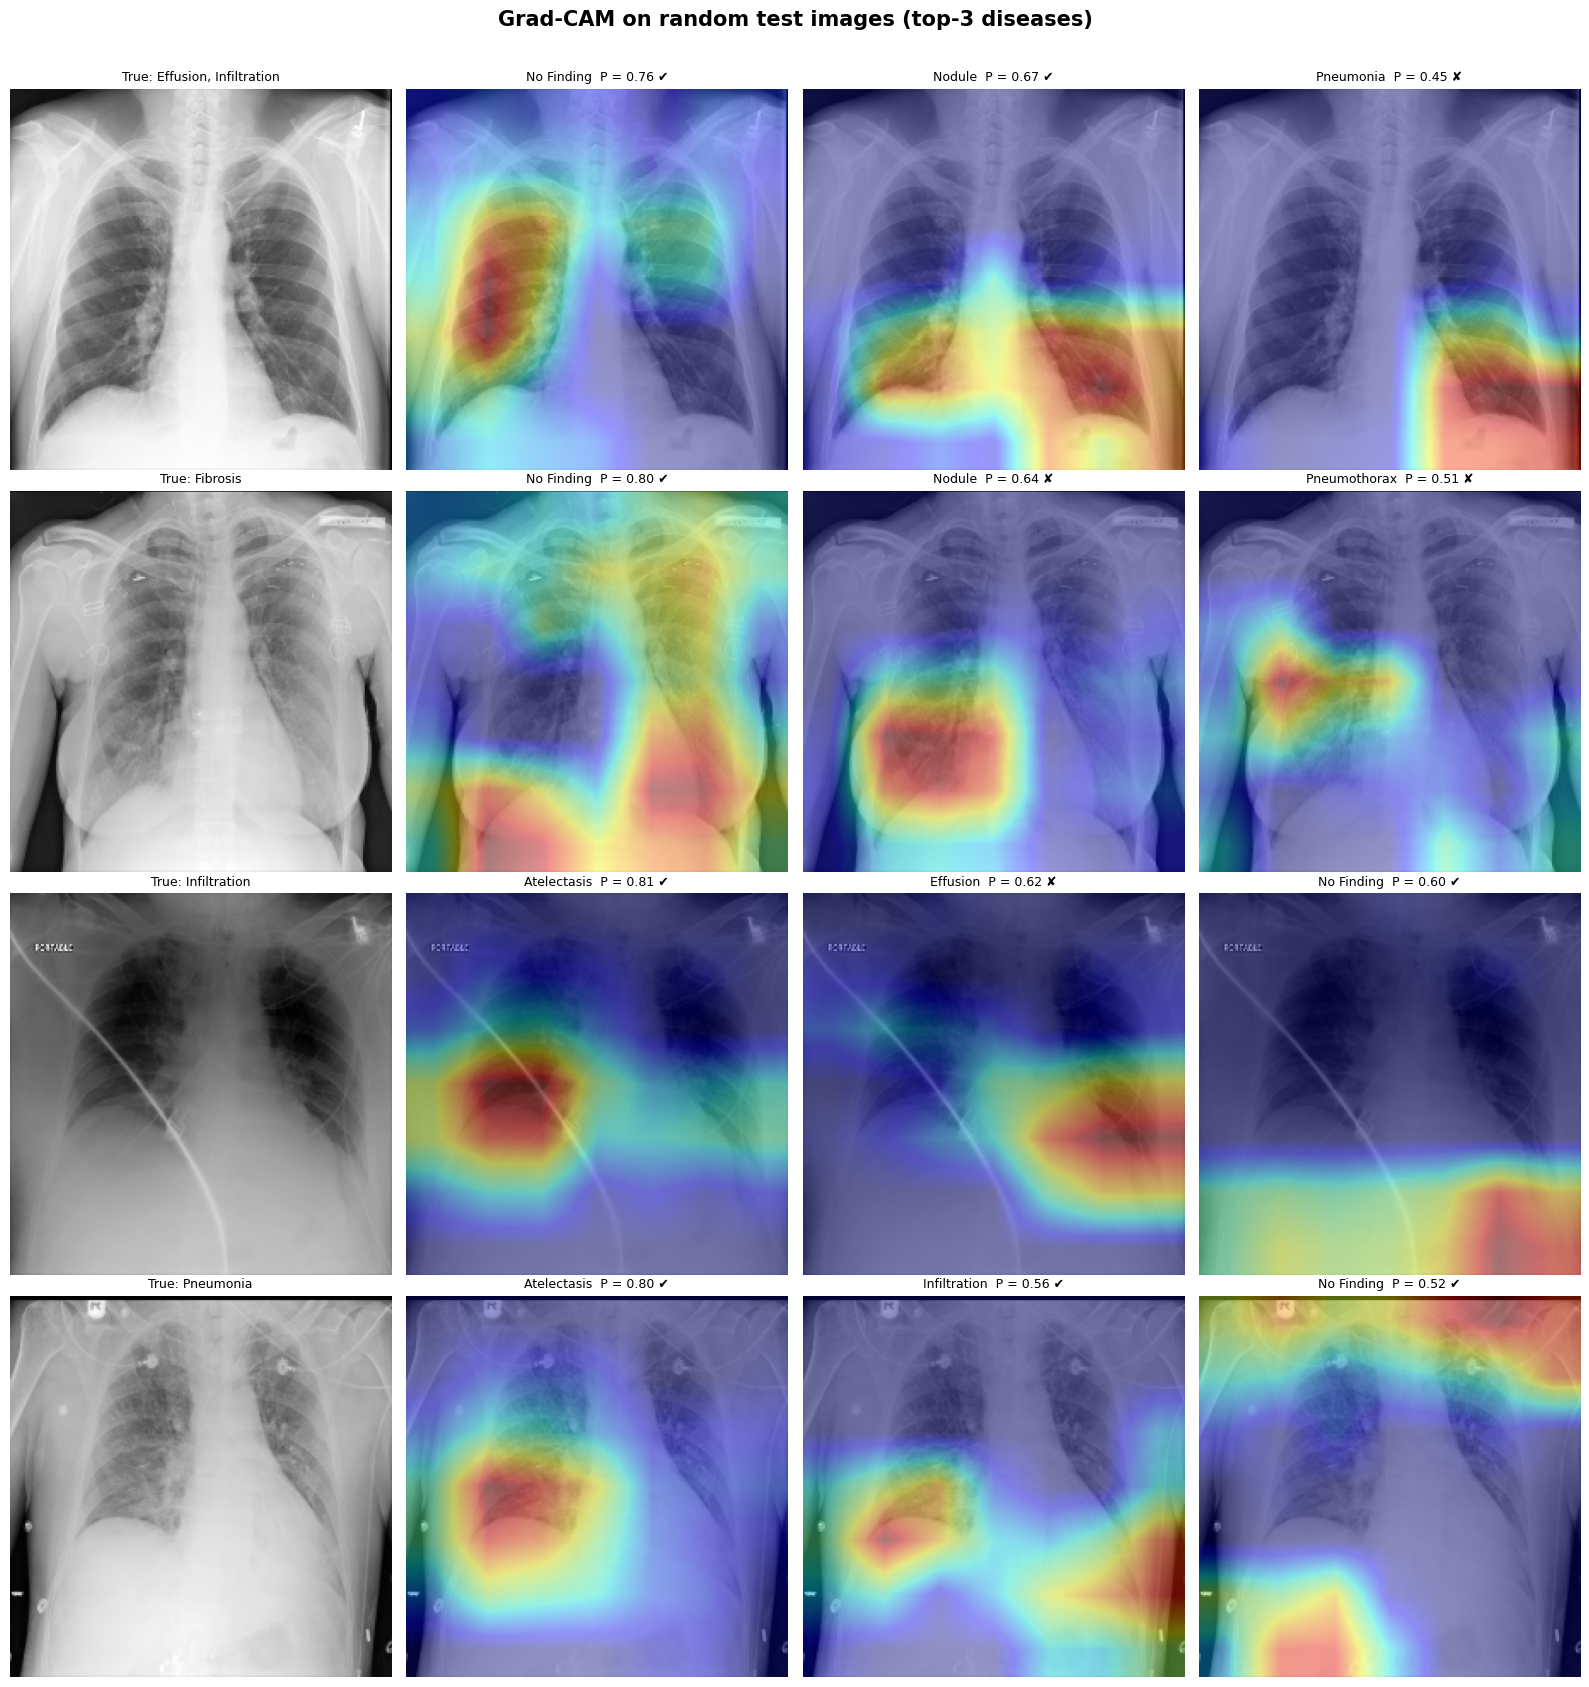

In [ ]:
def plot_top_k(rows, top_k=3, title="", save_path=None):
    fig, axes = plt.subplots(len(rows), top_k + 1, figsize=(4 * (top_k + 1), 4.3 * len(rows)), squeeze=False)
    for r, row_idx in enumerate(rows):
        path = test_df.loc[row_idx, "image_path"]
        img  = load_image(path)
        axes[r, 0].imshow(np.asarray(img).mean(axis=-1), cmap="gray"); axes[r, 0].axis("off")
        axes[r, 0].set_title("True: " + ", ".join(test_df.loc[row_idx, "labels_list"]), fontsize=9)
        for k, i in enumerate(np.argsort(test_prob[row_idx])[::-1][:top_k], start=1):
            cam, prob = grad_cam(img, i)
            mark = "✔" if prob >= thresholds[i] else "✘"
            show_cam(axes[r, k], img, cam, f"{classes[i]}  P = {prob:.2f} {mark}")
    plt.suptitle(title, fontsize=15, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


sick_rows = test_df.index[test_df["labels_list"].apply(lambda l: l != ["No Finding"])].tolist()
random_rows = random.sample(sick_rows, min(4, len(sick_rows)))
plot_top_k(random_rows, title="Grad-CAM on random test images (top-3 diseases)",
           save_path=XAI_DIR / "gradcam_random_images.png")

## 6. Grad-CAM — missed cases
Images that have a disease the model **missed** (probability below its threshold). The heatmap shows where the model looked for that disease — useful for discussing the model's limits.

Missed (image, disease) pairs in the test set: 1935


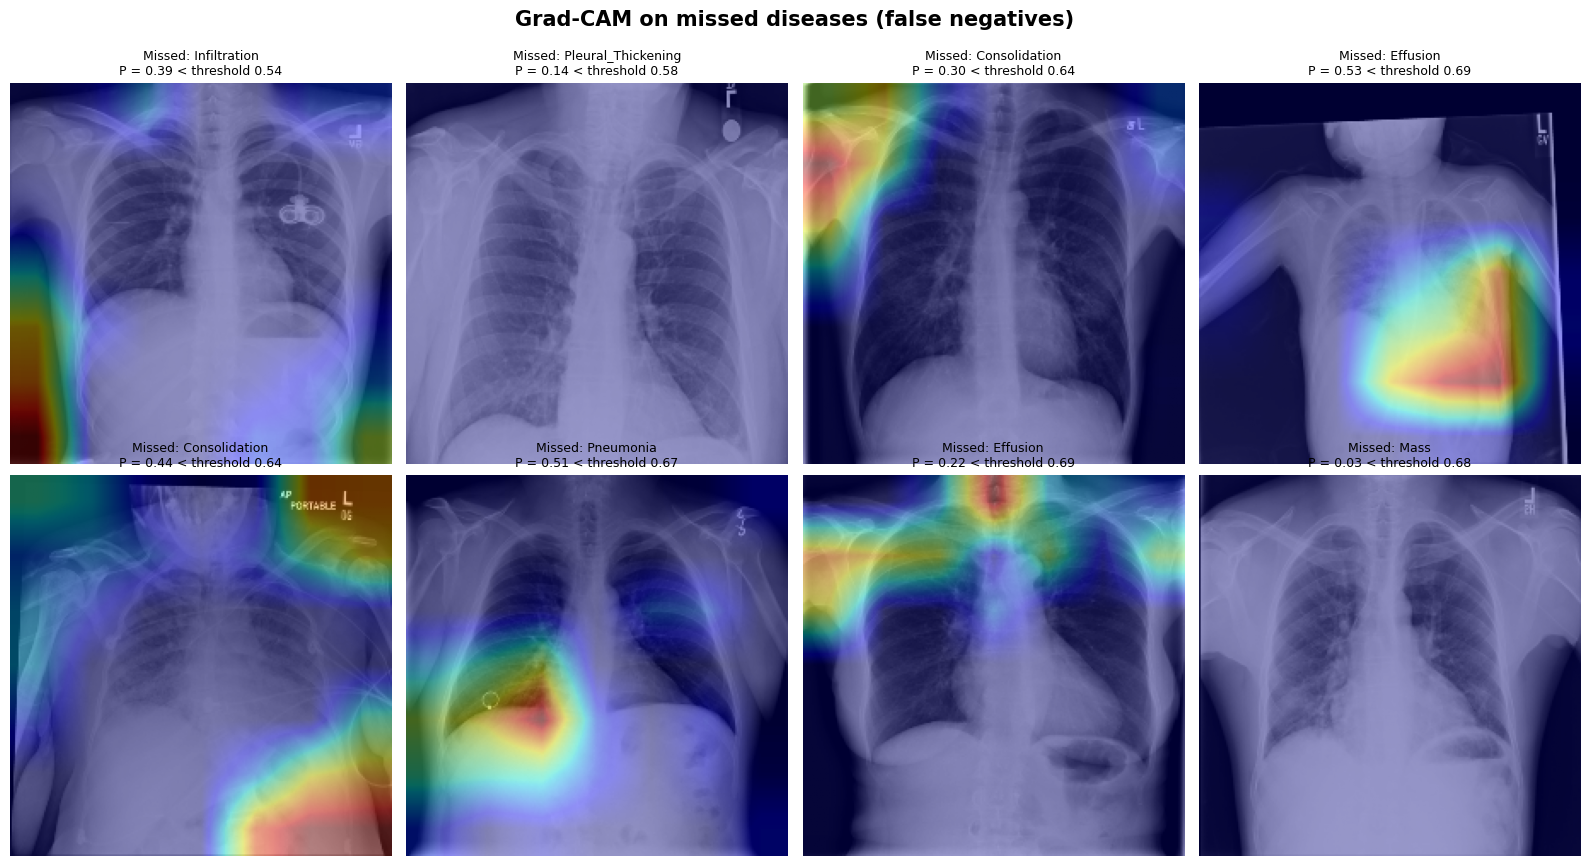

In [ ]:
missed = [(r, i) for r in range(len(test_df)) for i, c in enumerate(classes)
          if c != "No Finding" and y_test[r, i] == 1 and test_pred[r, i] == 0]
print("Missed (image, disease) pairs in the test set:", len(missed))

if missed:
    sample = random.sample(missed, min(8, len(missed)))
    n_rows = int(np.ceil(len(sample) / 4))
    fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4.4 * n_rows), squeeze=False)
    for ax, (r, i) in zip(axes.flat, sample):
        img = load_image(test_df.loc[r, "image_path"])
        cam, prob = grad_cam(img, i)
        show_cam(ax, img, cam, f"Missed: {classes[i]}\nP = {prob:.2f} < threshold {thresholds[i]:.2f}")
    for ax in axes.flat[len(sample):]:
        ax.axis("off")
    plt.suptitle("Grad-CAM on missed diseases (false negatives)", fontsize=15, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(XAI_DIR / "gradcam_missed_cases.png", dpi=150, bbox_inches="tight")
    plt.show()

## 7. Explain any X-ray
Upload an image (or give a path) and get the probabilities plus the Grad-CAM of the top diseases.

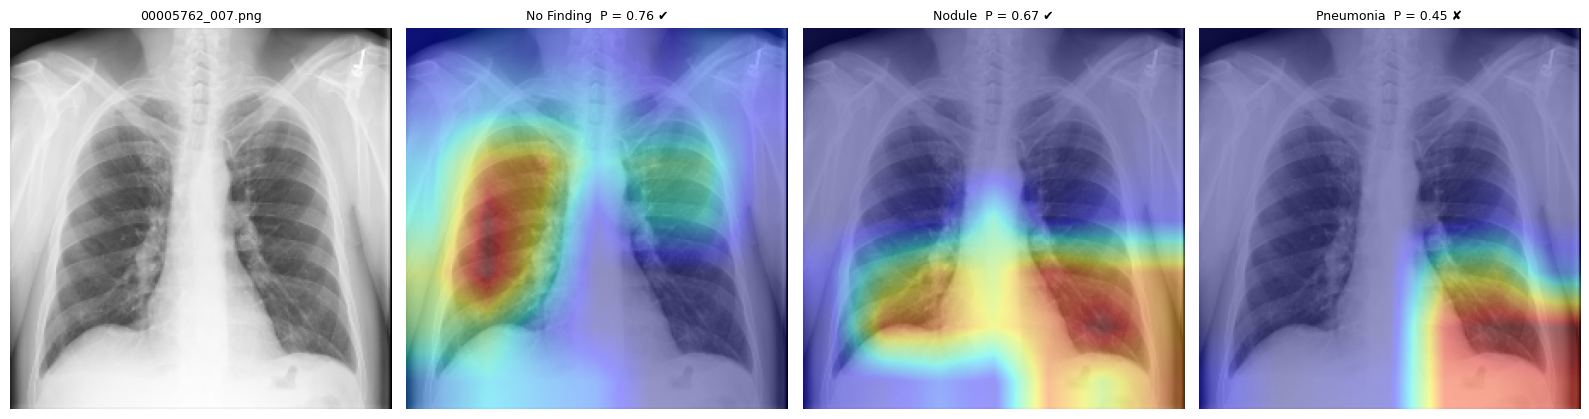

,Disease,Probability,Threshold,Detected
0,No Finding,0.764,0.372,True
1,Nodule,0.671,0.665,True
2,Pneumonia,0.452,0.666,False
3,Atelectasis,0.384,0.641,False
4,Mass,0.361,0.679,False
5,Fibrosis,0.273,0.711,False
6,Infiltration,0.271,0.540,False
7,Pleural_Thickening,0.270,0.578,False
8,Effusion,0.243,0.685,False
9,Consolidation,0.193,0.638,False


In [ ]:
def explain_image(path, top_k=3, save_path=None):
    img  = load_image(path)
    prob = model.predict(img[None, ...], verbose=0)[0]
    result = pd.DataFrame({"Disease": classes, "Probability": prob, "Threshold": thresholds})
    result["Detected"] = result["Probability"] >= result["Threshold"]
    result = result.sort_values("Probability", ascending=False).reset_index(drop=True)

    fig, axes = plt.subplots(1, top_k + 1, figsize=(4 * (top_k + 1), 4.3))
    axes[0].imshow(np.asarray(img).mean(axis=-1), cmap="gray"); axes[0].axis("off")
    axes[0].set_title(Path(path).name, fontsize=9)
    for k, disease in enumerate(result["Disease"][:top_k], start=1):
        i = classes.index(disease)
        cam, p = grad_cam(img, i)
        show_cam(axes[k], img, cam, f"{disease}  P = {p:.2f} {'✔' if p >= thresholds[i] else '✘'}")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return result.round(3)


# Example on a test image
display(explain_image(test_df.loc[random_rows[0], "image_path"], save_path=XAI_DIR / "explain_example.png"))

# Your own image:
# from google.colab import files
# uploaded = files.upload()
# display(explain_image(next(iter(uploaded))))

In [ ]:
print("Saved figures:")
for p in sorted(XAI_DIR.glob("*.png")):
    print("  ", p)

Saved figures:
   /content/drive/MyDrive/x_ray_ds/xai_run3/explain_example.png
   /content/drive/MyDrive/x_ray_ds/xai_run3/gradcam_missed_cases.png
   /content/drive/MyDrive/x_ray_ds/xai_run3/gradcam_per_disease.png
   /content/drive/MyDrive/x_ray_ds/xai_run3/gradcam_random_images.png


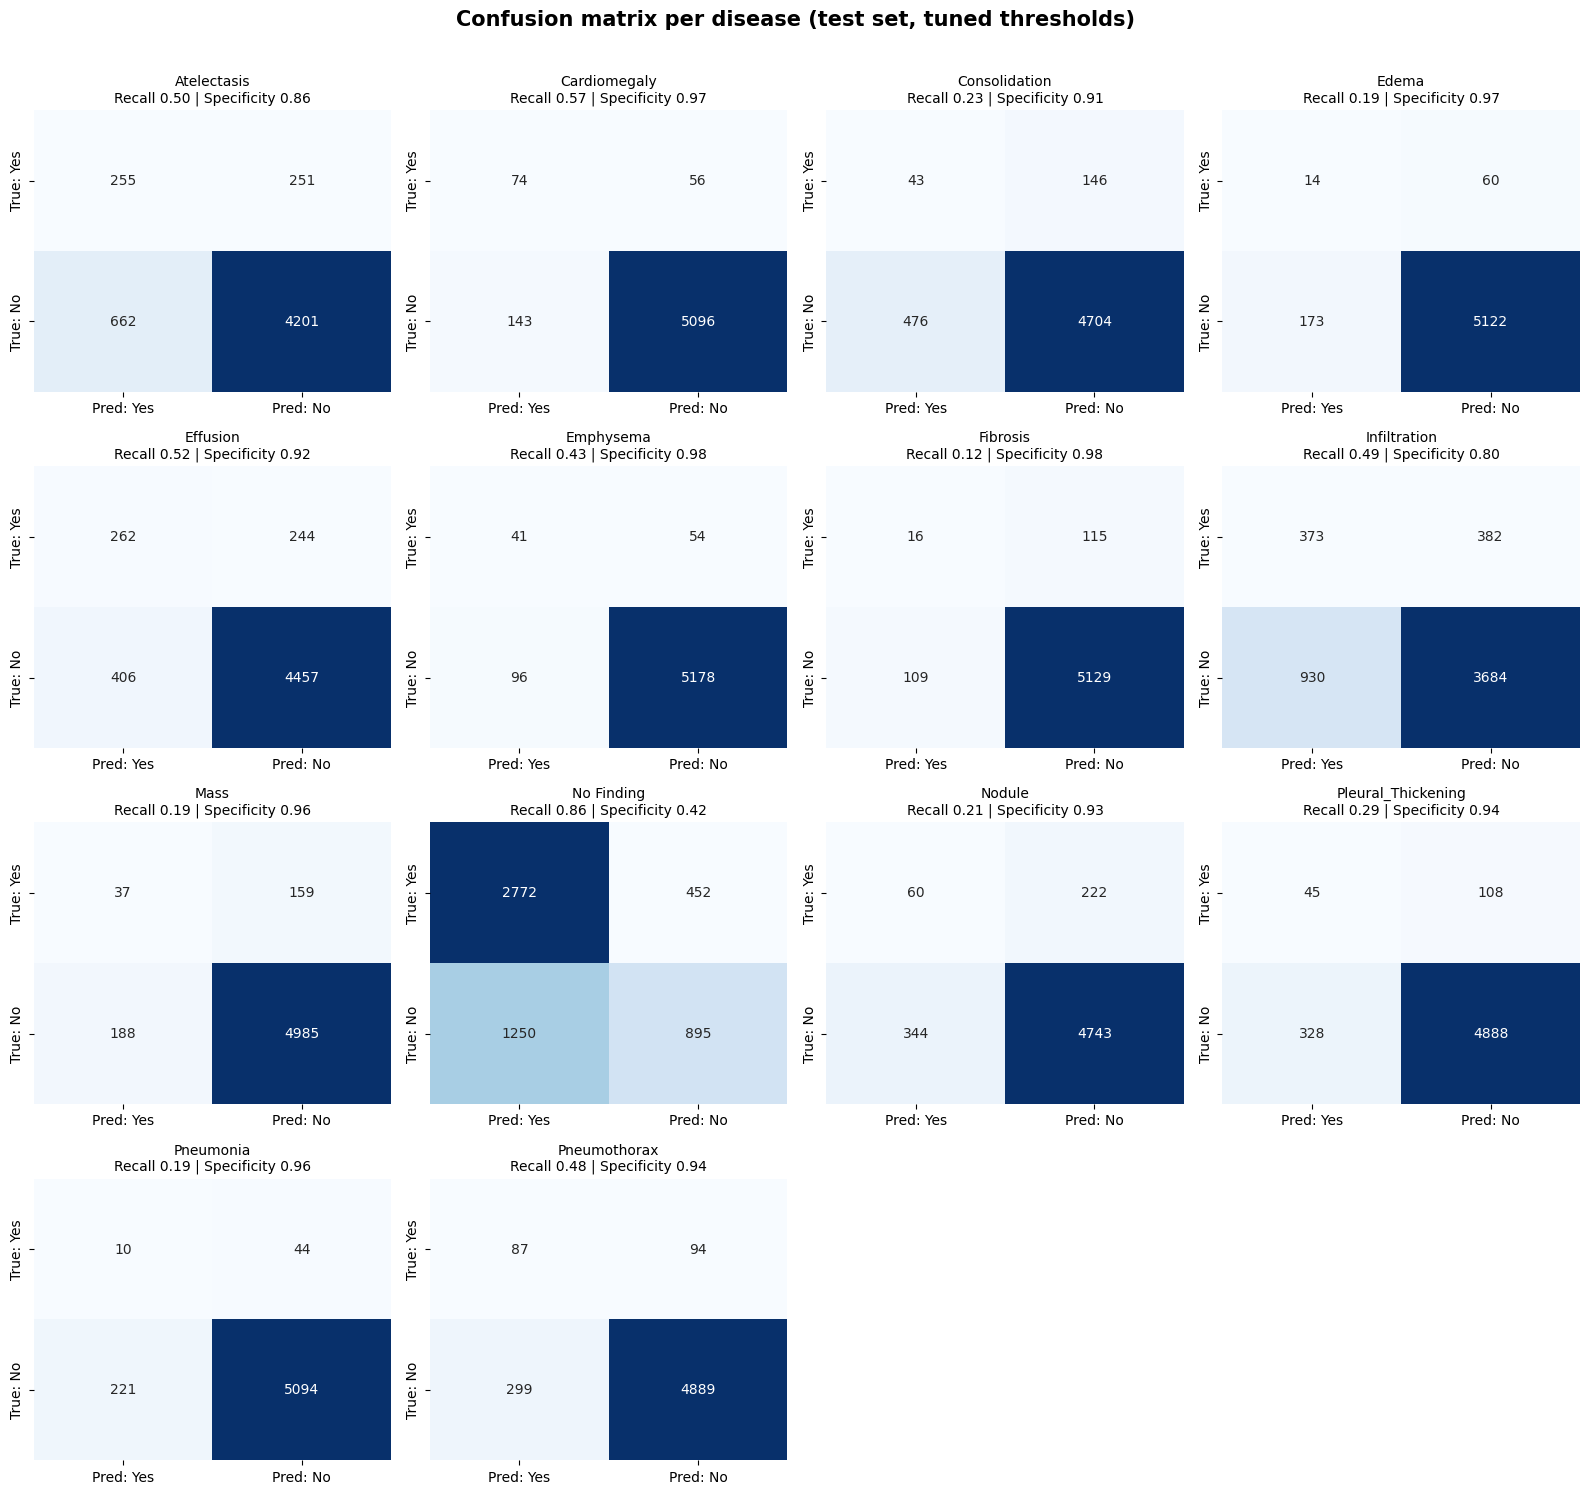

,TP,FN,FP,TN,Recall,Precision,Specificity
Disease,,,,,,,
Atelectasis,255,251,662,4201,0.504,0.278,0.864
Cardiomegaly,74,56,143,5096,0.569,0.341,0.973
Consolidation,43,146,476,4704,0.228,0.083,0.908
Edema,14,60,173,5122,0.189,0.075,0.967
Effusion,262,244,406,4457,0.518,0.392,0.917
Emphysema,41,54,96,5178,0.432,0.299,0.982
Fibrosis,16,115,109,5129,0.122,0.128,0.979
Infiltration,373,382,930,3684,0.494,0.286,0.798
Mass,37,159,188,4985,0.189,0.164,0.964


In [ ]:
from sklearn.metrics import multilabel_confusion_matrix
import seaborn as sns

cms = multilabel_confusion_matrix(y_test, test_pred)   # one 2x2 matrix per disease

n_cols = 4
n_rows = int(np.ceil(NUM_CLASSES / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.8 * n_rows), squeeze=False)
rows = []
for ax, c, cm in zip(axes.flat, classes, cms):
    tn, fp, fn, tp = cm.ravel()
    sns.heatmap([[tp, fn], [fp, tn]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred: Yes", "Pred: No"], yticklabels=["True: Yes", "True: No"])
    ax.set_title(f"{c}\nRecall {tp / max(tp + fn, 1):.2f} | Specificity {tn / max(tn + fp, 1):.2f}", fontsize=10)
    rows.append({"Disease": c, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                 "Recall": tp / max(tp + fn, 1), "Precision": tp / max(tp + fp, 1),
                 "Specificity": tn / max(tn + fp, 1)})
for ax in axes.flat[NUM_CLASSES:]:
    ax.axis("off")
plt.suptitle("Confusion matrix per disease (test set, tuned thresholds)", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(XAI_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

cm_table = pd.DataFrame(rows).set_index("Disease")
cm_table.to_csv(XAI_DIR / "confusion_matrices.csv")
display(cm_table.round(3))